# Creacion de un CSV con Datos sinteticos para entrenar el modelo

In [ ]:
import pandas as pd
import numpy as np

# Datos base tomados de la tabla de dosificación
base_data = [
    {"cemento": 420, "arena": 0.67, "grava": 0.67, "psi": 4000, "mpa": 27},
    {"cemento": 380, "arena": 0.60, "grava": 0.76, "psi": 3555, "mpa": 24},
    {"cemento": 350, "arena": 0.55, "grava": 0.84, "psi": 3224, "mpa": 22},
    {"cemento": 320, "arena": 0.52, "grava": 0.90, "psi": 3000, "mpa": 20},
    {"cemento": 300, "arena": 0.48, "grava": 0.95, "psi": 2850, "mpa": 19},
    {"cemento": 280, "arena": 0.55, "grava": 0.95, "psi": 2700, "mpa": 18},
    {"cemento": 270, "arena": 0.72, "grava": 0.83, "psi": 2400, "mpa": 16},
    {"cemento": 260, "arena": 0.63, "grava": 0.83, "psi": 2275, "mpa": 15},
    {"cemento": 230, "arena": 0.55, "grava": 0.92, "psi": 2000, "mpa": 14},
    {"cemento": 210, "arena": 0.50, "grava": 1.00, "psi": 1700, "mpa": 12},
    {"cemento": 175, "arena": 0.55, "grava": 0.98, "psi": 1560, "mpa": 11},
    {"cemento": 160, "arena": 0.55, "grava": 1.03, "psi": 1420, "mpa": 10}
]

# Parámetros
w_c_min = 0.35
w_c_max = 0.75
np.random.seed(42)

synthetic_data_adjusted = []

for row in base_data:
    for _ in range(1000):
        cement = np.random.normal(row["cemento"], row["cemento"] * 0.02)
        sand = np.random.normal(row["arena"], row["arena"] * 0.02)
        gravel = np.random.normal(row["grava"], row["grava"] * 0.02)

        w_c_ratio = np.clip(np.random.normal(0.25 + 12000 / row["psi"], 0.02), w_c_min, w_c_max)

        humidity_sensor = 1023 * (1 - ((w_c_ratio - w_c_min) / (w_c_max - w_c_min)))
        humidity_sensor += np.random.normal(0, 15)
        humidity_sensor = int(np.clip(humidity_sensor, 0, 1023))

        resistencia_real = np.random.normal(row["psi"], row["psi"] * 0.03)
        resistencia_real = max(resistencia_real, 100)  # no permitir resistencias absurdamente bajas

        synthetic_data_adjusted.append({
            "cemento_kgm3": round(cement, 2),
            "arena_m3": round(sand, 3),
            "grava_m3": round(gravel, 3),
            "relacion_agua_cemento": round(w_c_ratio, 3),
            "humedad_sensor": humidity_sensor,
            "resistencia_psi": round(resistencia_real, 1),
            "resistencia_mpa": round(resistencia_real * 0.0703, 2)
        })

# Crear DataFrame
df_realista = pd.DataFrame(synthetic_data_adjusted)

# Guardar CSV
df_realista.to_csv("dataset_concreto_realista_ajustado.csv", index=False)

print("CSV generado con éxito: dataset_concreto_realista_ajustado.csv")


CSV generado con éxito: dataset_concreto_realista_ajustado.csv


# Modelo de Prediccion de Resistencia de Concreto con Redes Neuronales


   cemento_kgm3  arena_m3  grava_m3  relacion_agua_cemento  humedad_sensor  \
0        424.17     0.668     0.679                   0.75               0   
1        433.27     0.680     0.664                   0.75               0   
2        422.03     0.644     0.647                   0.75               0   
3        412.37     0.651     0.690                   0.75               1   
4        415.43     0.671     0.655                   0.75               0   

   resistencia_psi  resistencia_mpa  
0           3971.9           279.22  
1           3944.1           277.27  
2           4037.7           283.85  
3           3829.0           269.18  
4           3965.0           278.74  


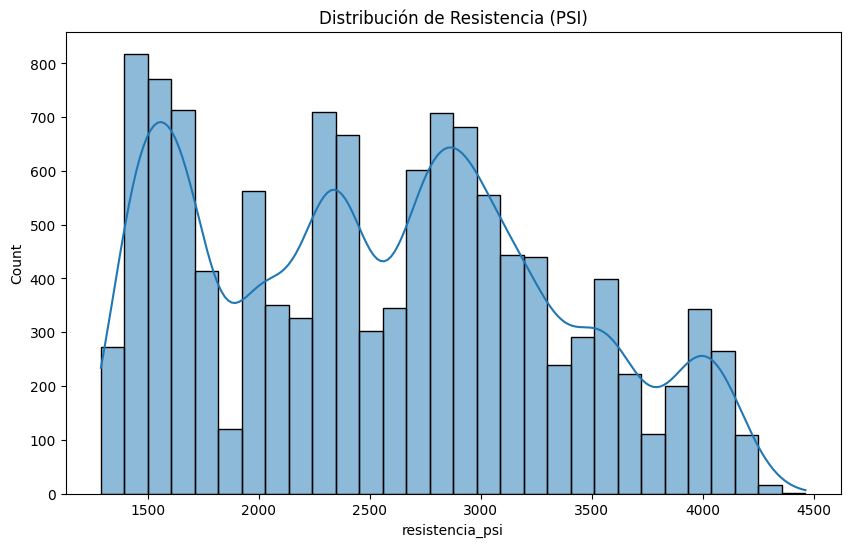

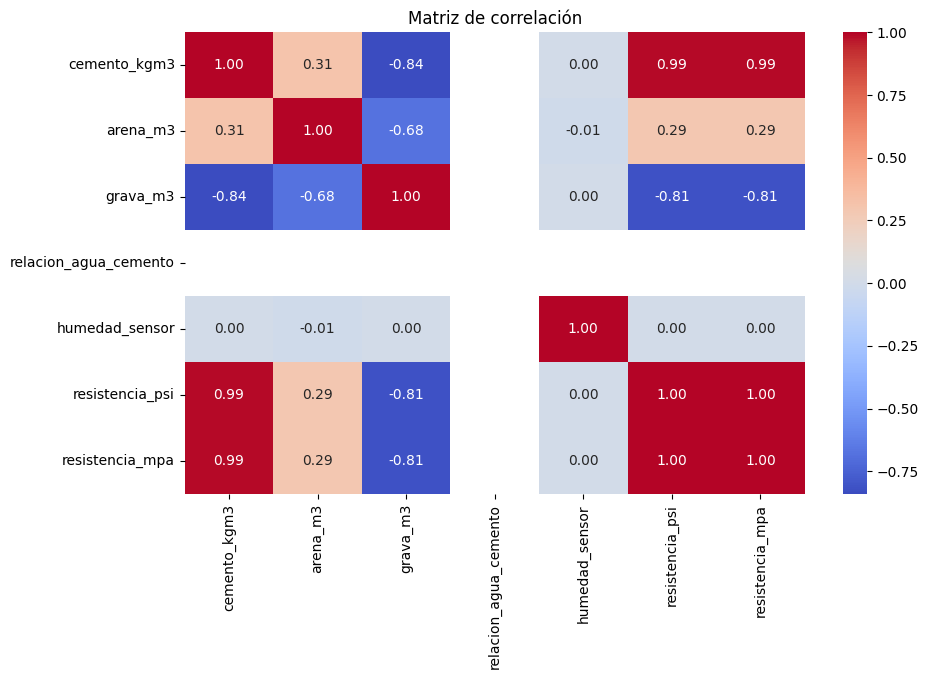

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/500
240/240 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 6802587.5000 - mae: 2499.2087 - val_loss: 4547891.5000 - val_mae: 2080.0361 - learning_rate: 0.0010
Epoch 2/500
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 2524910.7500 - mae: 1479.5667 - val_loss: 299716.9375 - val_mae: 470.4220 - learning_rate: 0.0010
Epoch 3/500
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 275844.9062 - mae: 412.9724 - val_loss: 32614.3164 - val_mae: 134.7740 - learning_rate: 0.0010
Epoch 4/500
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 221572.2188 - mae: 363.3385 - val_loss: 46536.3828 - val_mae: 145.6122 - learning_rate: 0.0010
Epoch 5/500
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 228864.4688 - mae: 368.3101 - val_loss: 30540.4141 - val_mae: 98.4051 - learning_rate: 0.0010
Epoch 6/500
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 195942.2656 - mae: 342.9120 - val_loss: 30565.3633 - val_mae: 122.5733 - learning_rate: 0.0010
Epoch 7/500
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - l

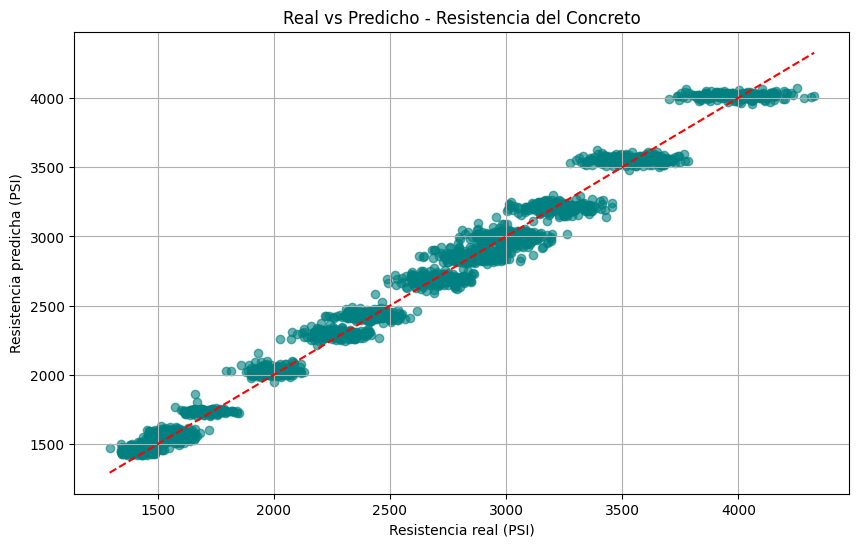

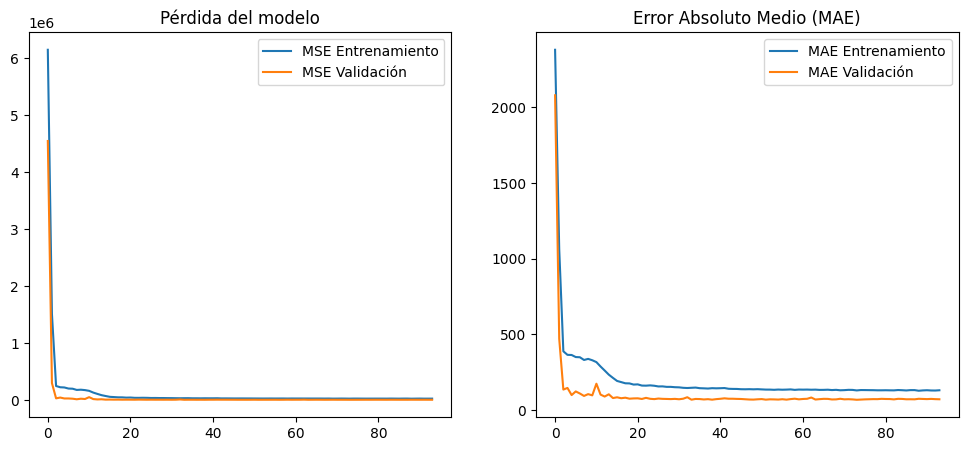

Modelo guardado como modelo_resistencia_concreto_profundo.h5


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import plot_model


file_path = "dataset_concreto_realista_ajustado.csv"
df = pd.read_csv(file_path)


print(df.head())


plt.figure(figsize=(10,6))
sns.histplot(df['resistencia_psi'], kde=True, bins=30)
plt.title("Distribución de Resistencia (PSI)")
plt.show()


plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de correlación")
plt.show()


X = df.drop(['resistencia_psi', 'resistencia_mpa'], axis=1)
y = df['resistencia_psi']


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


model = keras.Sequential([
    layers.Dense(512, activation='relu', input_shape=(X.shape[1],)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)  # salida: resistencia en PSI
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])


plot_model(model, to_file='modelo_red_neuronal.png', show_shapes=True, show_layer_names=True)


early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)


history = model.fit(X_train, y_train, epochs=500, validation_split=0.2, batch_size=32, verbose=1, callbacks=[early_stop, reduce_lr])


y_pred = model.predict(X_test).flatten()

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'MSE: {mse:.2f}')
print(f'MAE: {mae:.2f}')
print(f'R² Score: {r2:.4f}')


plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Resistencia real (PSI)')
plt.ylabel('Resistencia predicha (PSI)')
plt.title('Real vs Predicho - Resistencia del Concreto')
plt.grid(True)
plt.show()


plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='MSE Entrenamiento')
plt.plot(history.history['val_loss'], label='MSE Validación')
plt.legend()
plt.title('Pérdida del modelo')

plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='MAE Entrenamiento')
plt.plot(history.history['val_mae'], label='MAE Validación')
plt.legend()
plt.title('Error Absoluto Medio (MAE)')
plt.show()

#  Guardar el modelo entrenado
model.save("modelo_resistencia_concreto_profundo.h5")
print("Modelo guardado como modelo_resistencia_concreto_profundo.h5")

